# Solar PV Imports and Capacity Analysis (2019-2025)
### (11/1/2026)

Study area: North America and South America (Totally 15 countries)


In [1]:
%pip install pandas matplotlib plotly seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

print(pd.__version__)

3.1.0


In [3]:
df = pd.read_csv(
    "/workspaces/WangWangCheChen/data/Processed/CLEANED_Study_area_data_2018_2025.csv"
)

df.head()

,Area,Study_scope,Year,China_panel_exports_USD,China_panel_exports_MW,CleanTech_solarPV_USD,CleanTech_alltech_USD,PV_installed_capacity_MW,PV_generation_GWh,Population,PV_capacity_additions_MW,PV_installed_W_per_person
0,Canada,North America,2018,48086354,181.13,48121174,324210505,2631.0,3491.0,37072620,NaN,70.968817
1,Canada,North America,2019,62046149,235.58,62046216,501304576,2828.0,3752.0,37618495,197.0,75.175788
2,Canada,North America,2020,72110171,310.85,72110171,523513306,3068.0,4072.0,38028638,240.0,80.676042
3,Canada,North America,2021,59623578,222.12,59623578,857777248,3854.0,5115.0,38239864,786.0,100.784877
4,Canada,North America,2022,24636922,89.66,77003130,1107503288,4322.0,5737.0,38950132,468.0,110.962397


### Figure 1. Solar Panel Imports from China and PV Capacity Additions in North and South America (2019–2025)

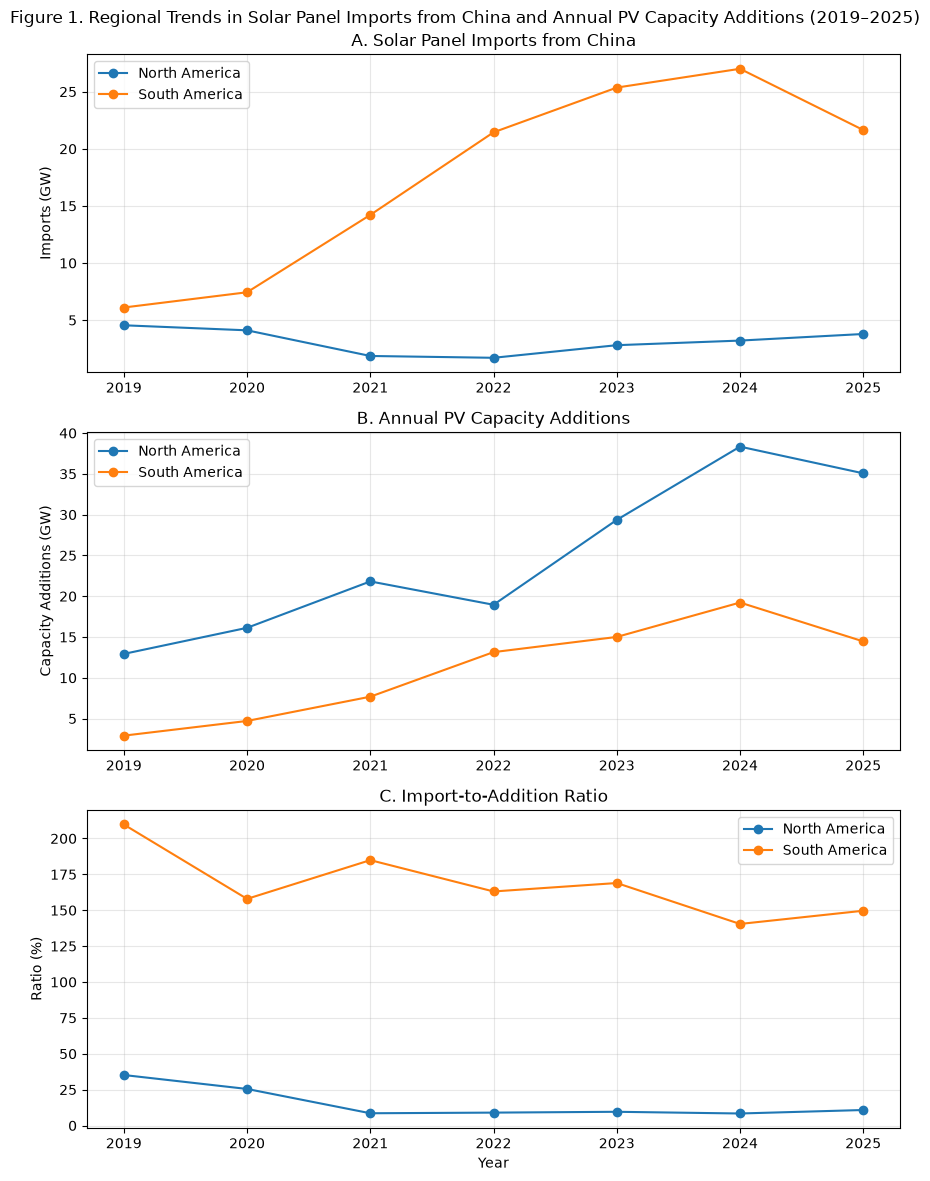

In [37]:
region = df.groupby(['Year', 'Study_scope'])[
    ['China_panel_exports_MW', 'PV_capacity_additions_MW']
].sum(min_count=1).reset_index()

# Calculate ratio
region['Ratio'] = (
    region['China_panel_exports_MW'] /
    region['PV_capacity_additions_MW'] * 100
)

# Remove 2018
region = region[region['Year'] >= 2019]

fig, axes = plt.subplots(3, 1, figsize=(9, 12))

for name, data in region.groupby('Study_scope'):
    axes[0].plot(data['Year'], 
                 data['China_panel_exports_MW'] / 1000,
                 marker='o', 
                 label=name)
    axes[1].plot(data['Year'], 
                 data['PV_capacity_additions_MW'] / 1000,
                 marker='o', 
                 label=name)
    axes[2].plot(data['Year'], 
                 data['Ratio'],
                 marker='o', 
                 label=name)

axes[0].set_title('A. Solar Panel Imports from China')
axes[0].set_ylabel('Imports (GW)')

axes[1].set_title('B. Annual PV Capacity Additions')
axes[1].set_ylabel('Capacity Additions (GW)')

axes[2].set_title('C. Import-to-Addition Ratio')
axes[2].set_ylabel('Ratio (%)')
axes[2].set_xlabel('Year')

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

fig.suptitle(
    'Figure 1. Regional Trends in Solar Panel Imports from China and Annual PV Capacity Additions (2019–2025)'
)
plt.tight_layout()
plt.show()

* Research Question: Do changes in China’s solar panel exports correlate with changes in the annual new photovoltaic (PV) installation capacity of destination countries?

* Observed Patterns: In South America and North America, the volume of solar panels imported from China exhibits different trends compared to annual new PV installation capacity. In South America, the volume of imports from China increased from 6.106 gigawatts (GW) in 2019 to 27.004 GW in 2024, before declining to 21.643 GW in 2025. In contrast, North America imported only 3.210 gigawatts from China in 2024, while its annual new PV installed capacity reached 38.336 gigawatts.

* Units: Both import volume and new installed capacity are measured in gigawatts (GW). The import-to-addition ratio is calculated as annual imports from China divided by annual PV capacity additions, multiplied by 100%.

* Limitations: Regional totals might be heavily influenced by large countries, particularly Brazil and the United States. Furthermore, imported solar panels may not necessarily be installed in the same year. Additionally, new PV installation capacity may include panels produced domestically or imported from other countries.

### Figure 2. Chinese Solar Panel Imports and PV Capacity Additions in 15 Countries (2019–2025)

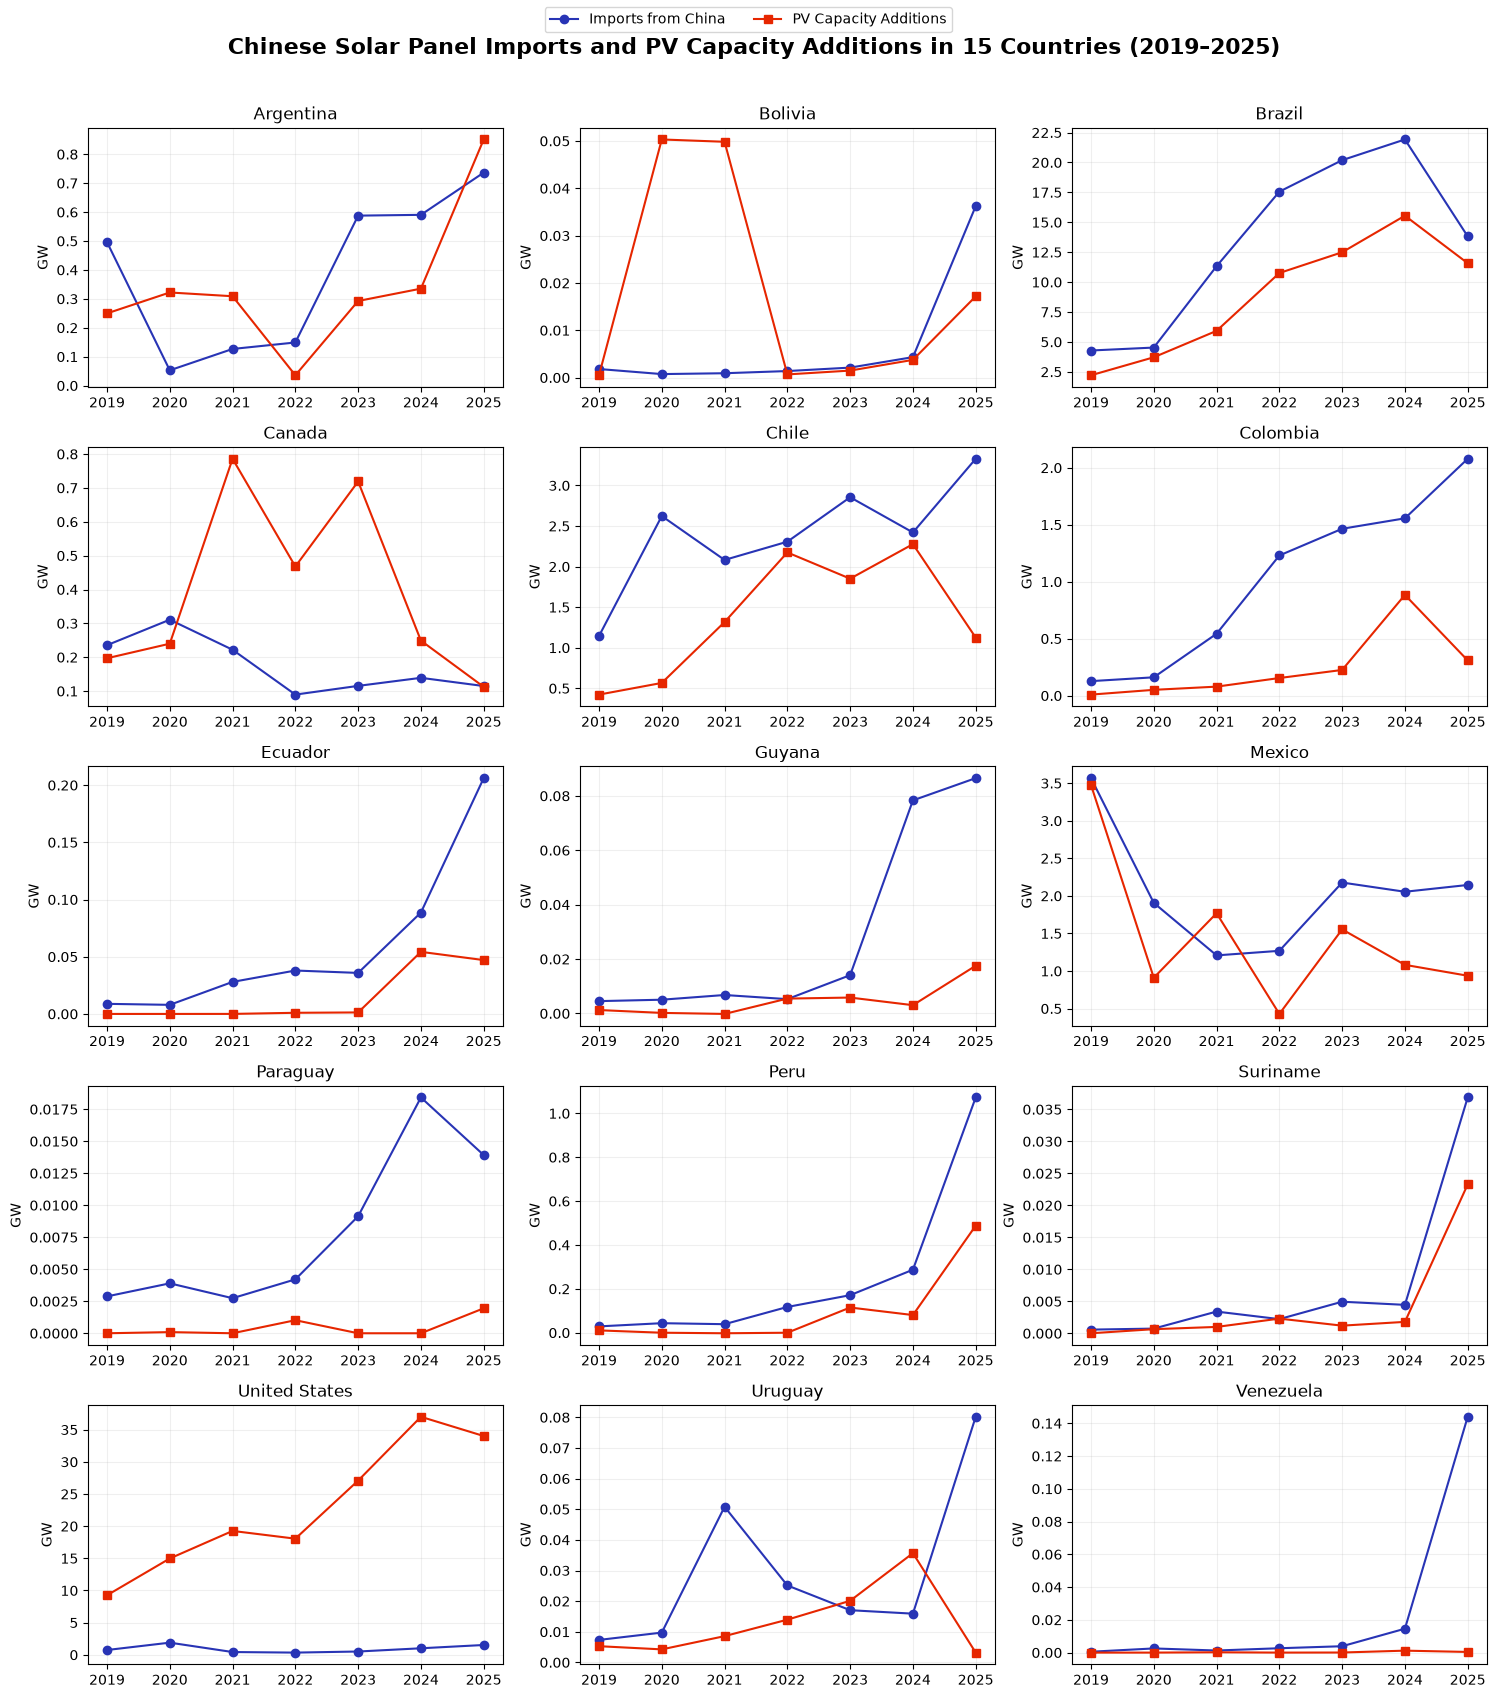

In [27]:
countries = sorted(df['Area'].unique())

fig, axes = plt.subplots(5, 3, figsize=(15, 17))
fig.suptitle(
    'Chinese Solar Panel Imports and PV Capacity Additions in 15 Countries (2019–2025)',
    fontsize=16,
    fontweight='bold'
)
for ax, country in zip(axes.flat, countries):
    data = df[(df['Area'] == country) & (df['Year'] >= 2019)]

    ax.plot(data['Year'], data['China_panel_exports_MW'] / 1000,
            marker='o', color="#2834B5", label='Imports from China')

    ax.plot(data['Year'], data['PV_capacity_additions_MW'] / 1000,
            marker='s', color="#E62600", label='PV Capacity Additions')

    ax.set_title(country)
    ax.set_ylabel('GW')
    ax.grid(alpha=0.2)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


* Research Question: How does the relationship between solar panel imports from China and the increase in photovoltaic installed capacity vary across different destination countries?

* Observed Patterns: This relationship varies significantly across countries. Taking Brazil as an example, the volume of imports from China increased from 4.282 gigawatts (GW) in 2019 to 21.924 GW in 2024, while the annual increase in new PV installed capacity during the same period rose from 2.212 GW to 15.551 GW. In contrast, in the United States, the annual net increase in PV installed capacity throughout the study period was far higher than the volume of direct imports from China. These differences indicate that countries do not follow a uniform pattern in terms of import and installation trends.

* Units: Both the annual volume of solar panels imported from China and the annual new PV installation capacity are measured in gigawatts (GW).

* Limitations: This chart does not account for imports from other suppliers or domestic solar panel production. Additionally, the vertical axis scales vary across the country-specific charts, limiting the ability to make direct visual comparisons of the magnitude of change.

### Table 1. Annual Solar Panel Imports from China and PV Capacity Additions by Country and Region (2019–2025)

In [42]:
data = df[df['Year'].between(2019, 2025)].copy()

data['Imports (GW)'] = data['China_panel_exports_MW'] / 1000
data['Additions (GW)'] = data['PV_capacity_additions_MW'] / 1000

metrics = ['Imports (GW)', 'Additions (GW)']
years = list(range(2019, 2026))

columns = pd.MultiIndex.from_product(
    [years, metrics]
)

country = data.pivot(
    index=['Study_scope', 'Area'],
    columns='Year',
    values=metrics
)

country = country.swaplevel(0, 1, axis=1)
country = country.reindex(columns=columns)

region = data.groupby(['Study_scope', 'Year'])[metrics].sum(min_count=1)
region = region.unstack('Year')
region = region.swaplevel(0, 1, axis=1)
region = region.reindex(columns=columns)

rows = []

for area in ['North America', 'South America']:
    countries = country.loc[area].sort_index()
    rows.append(countries)

    regional_total = region.loc[[area]].copy()
    regional_total.index = [area + ' Total']
    rows.append(regional_total)

summary_table = pd.concat(rows).round(3)
summary_table.loc['All Countries Total'] = (
    summary_table.loc['North America Total']
    + summary_table.loc['South America Total']
)

display(summary_table.round(3))
summary_table.to_csv(
    'Table1_Imports_Additions_2019_2025.csv',
    na_rep=''
)


2019                        2020                 \
                    Imports (GW) Additions (GW) Imports (GW) Additions (GW)   
Canada                     0.236          0.197        0.311          0.240   
Mexico                     3.568          3.476        1.907          0.910   
United States              0.747          9.256        1.890         14.977   
North America Total        4.550         12.929        4.108         16.128   
Argentina                  0.496          0.250        0.053          0.322   
Bolivia                    0.002          0.000        0.001          0.050   
Brazil                     4.282          2.212        4.528          3.716   
Chile                      1.145          0.423        2.623          0.567   
Colombia                   0.127          0.009        0.161          0.051   
Ecuador                    0.009          0.000        0.008          0.000   
Guyana                     0.005          0.001        0.005          0.000   
Paraguay                   0.003          0.000        0.004          0.000   
Peru                       0.029          0.011        0.043          0.000   
Suriname                   0.001          0.000        0.001          0.001   
Uruguay                    0.007          0.005        0.010          0.004   
Venezuela                  0.001          0.000        0.003          0.000   
South America Total        6.106          2.911        7.440          4.711   
All Countries Total       10.656         15.840       11.548         20.839   

                            2021                        2022                 \
                    Imports (GW) Additions (GW) Imports (GW) Additions (GW)   
Canada                     0.222          0.786        0.090          0.468   
Mexico                     1.208          1.769        1.269          0.429   
United States              0.433         19.260        0.345         18.056   
North America Total        1.863         21.815        1.703         18.953   
Argentina                  0.127          0.309        0.149          0.036   
Bolivia                    0.001          0.050        0.001          0.001   
Brazil                    11.328          5.924       17.561         10.759   
Chile                      2.082          1.317        2.307          2.175   
Colombia                   0.543          0.079        1.230          0.155   
Ecuador                    0.028          0.000        0.038          0.001   
Guyana                     0.007         -0.000        0.005          0.005   
Paraguay                   0.003          0.000        0.004          0.001   
Peru                       0.039         -0.002        0.117         -0.000   
Suriname                   0.003          0.001        0.002          0.002   
Uruguay                    0.051          0.009        0.025          0.014   
Venezuela                  0.001          0.000        0.003          0.000   
South America Total       14.213          7.686       21.443         13.149   
All Countries Total       16.076         29.501       23.146         32.102   

                            2023                        2024                 \
                    Imports (GW) Additions (GW) Imports (GW) Additions (GW)   
Canada                     0.115          0.719        0.139          0.249   
Mexico                     2.178          1.554        2.055          1.082   
United States              0.514         27.085        1.016         37.005   
North America Total        2.807         29.358        3.210         38.336   
Argentina                  0.588          0.293        0.590          0.335   
Bolivia                    0.002          0.001        0.004          0.004   
Brazil                    20.193         12.495       21.924         15.551   
Chile                      2.855          1.852        2.421          2.277   
Colombia                   1.464          0.226        1.556          0.884 

* Table 1 summarizes solar panel imports from China by 15 selected countries from 2019 to 2025, as well as the annual new photovoltaic (PV) installation capacity for each year. The data is presented in gigawatts (GW) and includes regional and overall totals for comparison. This table provides detailed numerical evidence supporting the regional and national trends presented in Figures 1 through 3.

### Figure 3. Imports from China vs. PV Capacity Additions (2024)

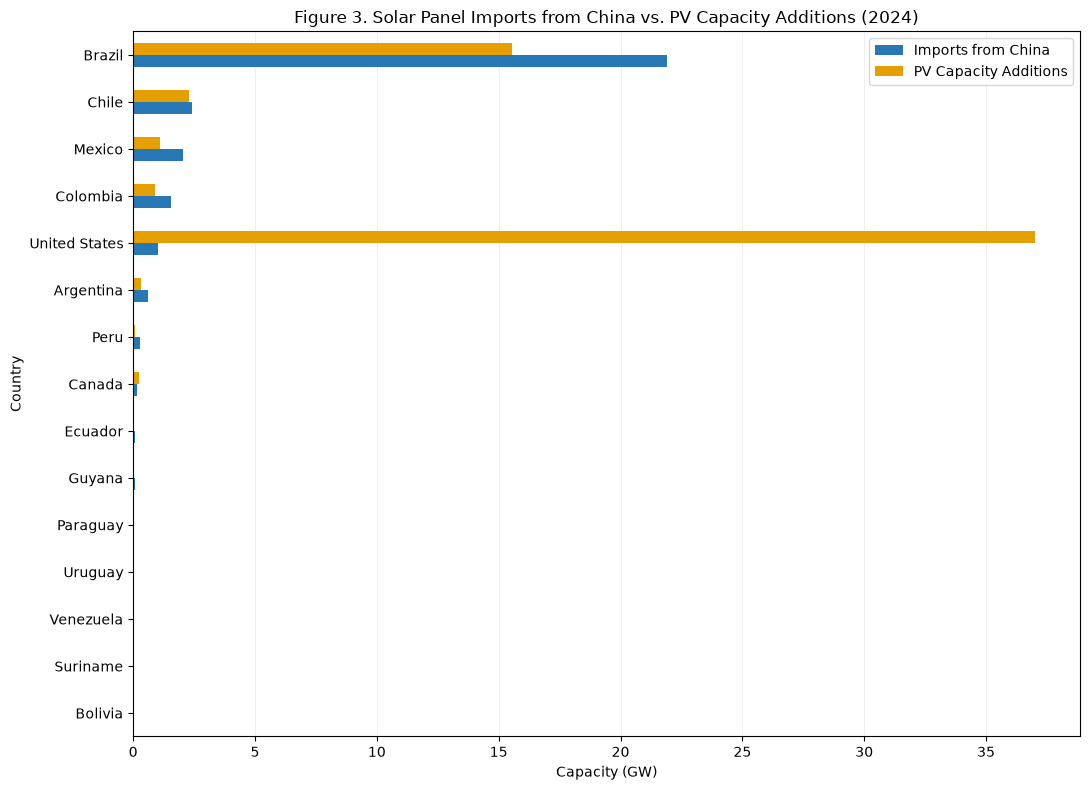

In [34]:
summary = df[df['Year'] == 2024].copy()

summary['Imports_GW'] = summary['China_panel_exports_MW'] / 1000
summary['Additions_GW'] = summary['PV_capacity_additions_MW'] / 1000

plot_data = summary.set_index('Area')[
    ['Imports_GW', 'Additions_GW']
]

plot_data = plot_data.sort_values('Imports_GW')

ax = plot_data.plot(
    kind='barh',
    figsize=(11, 8),
    color=['#2878B5', '#E69F00']
)

ax.set_xlabel('Capacity (GW)')
ax.set_ylabel('Country')
ax.set_title(
    'Figure 3. Solar Panel Imports from China vs. '
    'PV Capacity Additions (2024)'
)

ax.legend(['Imports from China', 'PV Capacity Additions'])
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


* Research Question: In 2024, which countries exhibited the greatest discrepancy between “imports from China” and “annual new solar PV installed capacity”?

* Observed Pattern: In 2024, there were significant differences among countries. The United States added 37.005 gigawatts (GW) of new PV capacity, but its direct imports from China totaled only 1.016 GW, resulting in a difference of 35.989 GW. Meanwhile, Brazil imported 21.924 GW of PV products from China, while its new PV capacity additions totaled 15.551 GW, resulting in a difference of 6.373 GW.

* Unit: Both variables above are measured in gigawatts (GW).

* Limitations: The difference between import volume and new PV installation capacity does not directly equate to “unmet demand” or “unused solar panels.” Imported products may be installed in subsequent years, and new installation capacity may also include panels from other sources.

### Key Findings

**Finding 1: Regional Differences in Solar Panel Imports and Annual PV Capacity Additions**

In 2024, the capacity of solar panels imported from China by the selected South American countries (27.004 GW) was substantially higher than that of the selected North American countries (3.210 GW). However, North America recorded substantially higher annual solar PV capacity additions (38.336 GW) than South America (19.227 GW). This contrast highlights differences between the two regions in their direct solar panel imports from China and domestic PV capacity expansion.

**Finding 2: Country-Level Differences Are Particularly Pronounced in the United States and Brazil**

In 2024, among the 15 countries studied, the United States exhibited the largest absolute difference between solar panel imports from China and annual PV capacity additions, with capacity additions exceeding imports by approximately 35.989 GW. Brazil, on the other hand, showed the opposite pattern, with imports from China exceeding annual PV capacity additions by approximately 6.373 GW. These differences highlight the variation in import and installation patterns across destination countries.

**Finding 3: Solar Panel Import Trends and PV Capacity Additions Do Not Always Move Together**

Throughout the study period, some countries experienced increases in both solar panel imports from China and annual PV capacity additions, while others exhibited divergent trends. This variation suggests that the relationship between imports from China and PV capacity additions is not consistent across all destination countries, highlighting the need for further correlation analysis to better understand these patterns.